This work, "Part 1, Topic 3, Lab B: DFA Attack on AES", is a derivative of "Recovering an AES key by Differential Fault Analysis attack" by Philippe Teuwen ([\@doegox](https://twitter.com/doegox)), used under CC BY SA. "Part 1, Topic 1, Lab B: DFA Attack on AES" is licensed under CC BY SA by NewAE Technology Inc. 

The original tutorial with minor modifications is available in the the `archive` folder of this repository. The original description, including attribution and changes is shown in the following block:

# Tutorial: Recovering an AES key by Differential Fault Analysis attack

Supported setups:

SCOPES:

* OPENADC

PLATFORMS:

* CWLITEARM
* CWLITEXMEGA

This tutorial will introduce you to the Differential Fault Analysis (DFA) attack. It will show you how to configure the  target to perform AES encryptions, how to glitch the encryption operations and introduce errors in the computed ciphertext and finally how to process these glitched ciphertexts to extract the AES key. This can be used as how-to for attacking other targets as well.

Original author: Philippe Teuwen ([\@doegox](https://twitter.com/doegox))

License: CC-BY-SA  

Improvements are welcome!



> **Thanks to Philippe Teuwen for contributing this tutorial, he was the winner of the ChipWhisperer 2018 Contest with this submission!**

This notebook has been updated to reflect changes with the ChipWhisperer API, work with the ChipWhisperer-Lite ARM, and with the above congratulatory message.

### On giants' shoulders
This tutorial is the first to deal with DFA, nevertheless it was not designed from scratch.
It relies on multiple sources we strongly encourage your to read as well for a better understanding of the details.

* The `simpleserial-aes` target firmware, which contains the software AES implementation used in other side-channel analysis tutorials such as [Using CW Analyzer for CPA Attack](PA_CPA_1-Using_CW-Analyzer_for_CPA_Attack.ipynb). This is the implementation we will attack.
* The glitching tutorials:
  * [Introduction to Glitch Attacks](Fault_1-Introduction_to_Clock_Glitch_Attacks.ipynb), useful to understand the hardware implementation of the glitching module
  * [Tutorial CW305-3 Clock Glitching (wiki)](https://wiki.newae.com/Tutorial_CW305-3_Clock_Glitching) which also presented briefly the principles of glitching AES, but without exploiting the faults
* The DFA attack itself: there is no DFA cryptanalysis code in the Chipwhisperer but we'll re-use a Python library the author of this tutorial wrote for attacking white-box implementations. It's called `phoenixAES` and it is available on [Github](https://github.com/SideChannelMarvels/JeanGrey) and on PyPI.

**SUMMARY:** *We saw in part A of this lab that we can insert faults into the 9th round of AES and, with enough faults and constant plaintext, we can recover the key. In this lab, we'll be trying this attack on a real target. Instead of performing the work manually, we'll be using PhoenixAES, which was written by Philippe Teuwen, author of the tutorial and blog post on which this lab is based. Later, we'll see how this attack can also be used on the 8th round instead.*

**LEARNING OUTCOMES**
* Identifying the 9th round of AES from a power trace
* Checking glitched ciphertexts for single byte fault criteria
* Faulting the 8th round of AES

In [1]:
SCOPETYPE = "OPENADC"
PLATFORM = "CW308_STM32F4"
CRYPTO_TARGET = "TINYAES128C"
# SS_VER='SS_VER_2_1'

## Prerequisites

### Building the target firmware

If you have the `avr-gcc` toolchain installed, you should be able to build the `simpleserial-aes-CW303` firmware:

In [2]:
import os
os.environ["PATH"] = "/opt/gcc-arm-none-eabi-10/bin:" + os.environ["PATH"]

In [3]:
%%bash -s "$PLATFORM" "$CRYPTO_TARGET"
cd ../../../firmware/mcu/simpleserial-aes
make PLATFORM=$1 CRYPTO_TARGET=$2

Building for platform CW308_STM32F4 with CRYPTO_TARGET=TINYAES128C
SS_VER set to SS_VER_1_1
SS_VER set to SS_VER_1_1
Blank crypto options, building for AES128


.
Welcome to another exciting ChipWhisperer target build!!
arm-none-eabi-gcc (GNU Arm Embedded Toolchain 10.3-2021.10) 10.3.1 20210824 (release)
Copyright (C) 2020 Free Software Foundation, Inc.
This is free software; see the source for copying conditions.  There is NO
warranty; not even for MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.

Size after:
   text	   data	    bss	    dec	    hex	filename
   4988	    544	   2020	   7552	   1d80	simpleserial-aes-CW308_STM32F4.elf
+--------------------------------------------------------
+ Built for platform CW308T: STM32F4 Target with:
+ CRYPTO_TARGET = TINYAES128C
+ CRYPTO_OPTIONS = AES128C
+--------------------------------------------------------


## Attack setup

### CW-lite connection and target flashing

Connect to the Chipwhisperer:

In [4]:
%run "../../Setup_Scripts/Setup_Generic.ipynb"

INFO: Found ChipWhisperer😍
scope.gain.mode                          changed from low                       to high                     
scope.gain.gain                          changed from 0                         to 22                       
scope.gain.db                            changed from 15.0                      to 25.091743119266056       
scope.adc.samples                        changed from 131124                    to 5000                     
scope.adc.trig_count                     changed from 42026                     to 22255856                 
scope.clock.clkgen_freq                  changed from 0                         to 7370129.87012987         
scope.clock.adc_freq                     changed from 0                         to 29480519.48051948        
scope.clock.extclk_monitor_enabled       changed from True                      to False                    
scope.clock.extclk_tolerance             changed from 1144409.1796875           to 13096723.705530167

Flash the target:

In [5]:
fw_path = "../../../firmware/mcu/simpleserial-aes/simpleserial-aes-{}.hex".format(PLATFORM)
cw.program_target(scope, prog, fw_path)

Detected known STMF32: STM32F40xxx/41xxx
Extended erase (0x44), this can take ten seconds or more
Attempting to program 6623 bytes at 0x8000000
STM32F Programming flash...
STM32F Reading flash...
Verified flash OK, 6623 bytes


In [6]:
if PLATFORM == "CWLITEXMEGA":
    def reboot_flush():            
        scope.io.pdic = False
        time.sleep(0.1)
        scope.io.pdic = "high_z"
        time.sleep(0.1)
        #Flush garbage too
        target.flush()
else:
    def reboot_flush():            
        scope.io.nrst = False
        time.sleep(0.05)
        scope.io.nrst = "high_z"
        time.sleep(0.05)
        #Flush garbage too
        target.flush()

### First execution

For the DFA attack, we need a constant plaintext (and constant key of course).
We could just use two bytearrays but let's use the CW API to demonstrate its usage.


In [9]:
ktp = cw.ktp.Basic()
ktp.fixed_text = True
ktp.fixed_key = True
key, text = ktp.next()

Assuming we want to record traces, let's capture the entire AES.  
It's useful to see which round(s) we'll glitch by tuning `scope.glitch.ext_offset` later.

In [10]:
scope.clock.adc_src = "clkgen_x1"
if PLATFORM == "CWLITEXMEGA" or PLATFORM == "CW303":
    scope.adc.samples = 20000
elif PLATFORM == "CWLITEARM" or PLATFORM == "CW308_STM32F4":
    scope.adc.samples = 8000

(ChipWhisperer Scope WARNING|File ChipWhispererHuskyClock.py:1191) scope.clock.adc_src is provided for backwards compability, but scope.clock.clkgen_src and scope.clock.adc_mul should be used for Husky.


Let's test our setup with a first execution, without fault.
It will give us the golden reference output.

In [11]:
reset_target(scope)
# make sure glitches are disabled (in case cells are re-run)
scope.io.hs2 = "clkgen"

trace = cw.capture_trace(scope, target, text, key)
goldciph = trace.textout
print("Plaintext: {}".format(text.hex()))
print("Key:       {}".format(key.hex()))
print("Ciphertext:{}".format(goldciph.hex()))

Plaintext: 000102030405060708090a0b0c0d0e0f
Key:       2b7e151628aed2a6abf7158809cf4f3c
Ciphertext:50fe67cc996d32b6da0937e99bafec60


In [12]:
reset_target(scope)

Just to be sure, let's check...

In [13]:
from Crypto.Cipher import AES
aes = AES.new(bytes(key), AES.MODE_ECB)
goldciph2 = aes.encrypt(bytes(text))
print("Expected ciphertext:  {}".format(goldciph2.hex()))

Expected ciphertext:  50fe67cc996d32b6da0937e99bafec60


Let's draw the full AES execution

<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
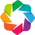

:Overlay
   .Curve.I           :Curve   [x]   (y)
   .Path.A_8th_round  :Path   [x,y]
   .Path.A_9th_round  :Path   [x,y]
   .Path.A_10th_round :Path   [x,y]

In [14]:
import holoviews as hv
from holoviews import opts
hv.extension('bokeh')
curve = hv.Curve(trace.wave).opts(width=600, height=600)

# add boxes around last rounds

if PLATFORM == "CWLITEXMEGA" or PLATFORM == "CW303":
    line = hv.Path([(11600, -0.25), (11600, 0.25), (13200, 0.25), (13200, -0.25), (11600, -0.25)], label='8th round').opts(color="red", show_legend=True) * \
            hv.Path([(13250, -0.25), (13250, 0.25), (14850, 0.25), (14850, -0.25), (13250, -0.25)], label='9th round').opts(color="green", show_legend=True) * \
            hv.Path([(14900, -0.25), (14900, 0.25), (16000, 0.25), (16000, -0.25), (14900, -0.25)], label='10th round').opts(color="yellow", show_legend=True)
elif PLATFORM == "CWLITEARM" or PLATFORM == "CW308_STM32F4":
    line = hv.Path([(5050, -0.1), (5050, 0.2), (5740, 0.2), (5740, -0.1), (5050, -0.1)], label='8th round').opts(color="red", show_legend=True) * \
            hv.Path([(5740, -0.1), (5740, 0.2), (6425, 0.2), (6425, -0.1), (5740, -0.1)], label='9th round').opts(color="green", show_legend=True) * \
            hv.Path([(6425, -0.1), (6425, 0.2), (6820, 0.2), (6820, -0.1), (6425, -0.1)], label='10th round').opts(color="yellow", show_legend=True)
    pass

#plt.show()
(curve * line).opts(opts.Path(line_width=3)).opts(width=600, height=600)

We see clearly the 10 AES-128 rounds, the 10th round being smaller than the others as there is no *MixColumn*.

### First glitches

To check the actual clock glitches with an oscilloscope, you can probe pin 6 of the CW 20 pin connector and run the following function to glitch all clock cycles during 2 seconds. Beware that the probe influences slightly the signal and it's enough to require a different tuning of the glitching parameters, so when you're attacking a target, do it all with or all without the oscilloscope but avoid messing up your setup!
In this tutorial, parameters were tuned without attached probe. Still, your board might require slightly different values.

In [15]:
import time
if scope._is_husky:
    scope.glitch.enabled = True

# These width/offset numbers are for CW-Lite/Pro; for CW-Husky, convert as per Fault 1_1:
def test_glitches():
    if PLATFORM == "CWLITEXMEGA" or PLATFORM == "CW303":
        scope.io.hs2 = "glitch"
        scope.glitch.clk_src = 'clkgen'
        scope.glitch.width=3.5
        scope.glitch.offset=34
        scope.glitch.trigger_src='continuous'
    elif PLATFORM == "CWLITEARM" or PLATFORM == "CW308_STM32F4":
        scope.io.hs2 = "glitch"
        scope.glitch.clk_src = "clkgen"
        scope.glitch.width = 650
        scope.glitch.offset = 4300
        scope.glitch.trigger_src='continuous'

def stop_test_glitches():
    scope.glitch.trigger_src='ext_single'

test_glitches()
time.sleep(2)
stop_test_glitches()

(ChipWhisperer Glitch WARNING|File ChipWhispererGlitch.py:196) clkgen unsupported for Husky; using pll instead.


Here is an example of five glitched clock cycles as seen with an oscilloscope:

![clock_glitches.png](img/clock_glitches.png)


See how the actual width and offset values are rounded to the internal step values.

In [14]:
print(scope.glitch)

enabled           = True
num_glitches      = 1
clk_src           = pll
mmcm_locked       = True
width             = 650
offset            = 4300
trigger_src       = ext_single
arm_timing        = after_scope
ext_offset        = 0
repeat            = 1
output            = clock_xor
phase_shift_steps = 4592



Let's see the effect of clock glitches on the AES execution.

In [16]:
# Initial glitch parameters
# These width/offset numbers are for CW-Lite/Pro; for CW-Husky, convert as per Fault 1_1:
if PLATFORM == "CWLITEXMEGA" or PLATFORM == "CW303":
    scope.io.hs2 = "glitch"
    scope.glitch.clk_src = 'clkgen'
    scope.glitch.width=3.5
    scope.glitch.offset=34
    scope.glitch.trigger_src='ext_single'
    scope.glitch.ext_offset = 13000
elif PLATFORM == "CWLITEARM" or PLATFORM == "CW308_STM32F4":
    scope.io.hs2 = "glitch"
    scope.glitch.clk_src = "clkgen"
    scope.glitch.width = 650
    scope.glitch.offset = 4300
    scope.glitch.ext_offset = 5400
    scope.glitch.repeat = 3
    scope.glitch.trigger_src='ext_single'

# reset target
reset_target(scope)
time.sleep(0.1)
trace = cw.capture_trace(scope, target, text, key)

(ChipWhisperer Glitch WARNING|File ChipWhispererGlitch.py:196) clkgen unsupported for Husky; using pll instead.


In [17]:
curve = hv.Curve(trace.wave)
curve *= hv.Path([(scope.glitch.ext_offset, 0.25), (scope.glitch.ext_offset, -0.3)]).opts(color="red")
curve.opts(width=600, height=600)

:Overlay
   .Curve.I :Curve   [x]   (y)
   .Path.I  :Path   [x,y]

You should see a glitch in the power trace (blue) when the clock was glitched (red dotted line).  
As said earlier, glitch parameters may have to be adapted to your specific hardware.  Our experience is that a good `scope.glitch.width` is one just a bit smaller than one producing a clearly visible glitch in the power trace. E.g. the trace above was created with `scope.glitch.width=6*MIN_STEP` and we'll use `scope.glitch.width=5*MIN_STEP` in our attack. If this is not precise enough, consider tuning `scope.glitch.width_fine` too.

### Campaign setup

We can use the GlitchController to do all the setup work for us here. We'll be categorizing our data into a lot of different groups, which will allow us to nicely visualize the data after our campaign is done:

In [18]:
# get control over logging in order to be able to mask target execution errors,
# which can easily happen when glitching the target!
import logging
import chipwhisperer.common.results.glitch as glitch

# can 
gc = glitch.GlitchController(groups=["column0", "column1", "column2", "column3", "other", "reset", "normal"], parameters=["width", "offset", "ext_offset"])

The next cell defines the glitches campaign. Some of this probably looks pretty familliar from other glitching labs. We're doing a bit more work here to categorize the data. We're also making a table in `results` to display results later.

In [24]:
# Check if a single column is glitched
def check_column_glitch(glitched_ct, gold_ct, column):
    column_lookup = [[0, 13, 10, 7], [4, 1, 14, 11], [8, 5, 2, 15], [12, 9, 6, 3]]  # Shift rows
    for byte in column_lookup[column]:
        if glitched_ct[byte] == gold_ct[byte]:
            return False
    return True

outputs = []
results = []
obf = []
traces = []
categories = []
glitch_params_list = []

def campaign():
    # Initial glitch parameters
    global outputs, results, obf, traces, categories, glitch_params_list
    
    # Reset results arrays
    outputs = []
    results = [['target output', 'width', 'offset', 'extoffset', 'column_fault']]
    obf = []
    traces = []
    categories = []
    glitch_params_list = []
    
    # Glitch setup
    scope.io.hs2 = "glitch"
    scope.glitch.clk_src = 'clkgen'
    scope.glitch.trigger_src = 'ext_single'
    scope.glitch.enabled = True
    key, text = ktp.next()
    
    # Make sure correct key is loaded on target
    reboot_flush()
    target.simpleserial_write('k', key)
    target.simpleserial_wait_ack()
    
    for glitch_setting in gc.glitch_values():
        # Set glitch settings
        scope.glitch.offset = int(glitch_setting[1])
        scope.glitch.width = int(glitch_setting[0])
        scope.glitch.ext_offset = int(glitch_setting[2])
        
        # Do glitch
        target.flush()
        key, text = ktp.next()
        logging.getLogger().setLevel(logging.ERROR)
        
        scope.arm()
        target.simpleserial_write('p', text)
        
        ret = scope.capture()
        if ret:
            print("timeout!")
            reboot_flush()
            target.simpleserial_write('k', key)
            target.simpleserial_wait_ack()
            continue
        
        trace = scope.get_last_trace()  # Capture power trace after execution
        
        # Record output
        output = target.simpleserial_read_witherrors('r', 16, timeout=100, glitch_timeout=1)
        
        # Handle invalid output
        if not output['valid']:
            gc.add("reset", (scope.glitch.width, scope.glitch.offset, scope.glitch.ext_offset))
            reboot_flush()
            target.simpleserial_write('k', key)
            target.simpleserial_wait_ack()
            continue
        
        data = [bytes(output['payload']).hex(), scope.glitch.width, scope.glitch.offset, scope.glitch.ext_offset]
        
        # 🔥 Initialize category before conditionals
        category = "normal"

        # Normal output
        if output['payload'] == goldciph:
            gc.add("normal", (scope.glitch.width, scope.glitch.offset, scope.glitch.ext_offset))
            data.append(None)
            results.append(data)
        else:
            outputs.append(output['payload'])
            
            # Check for a glitch in each column of AES
            column_glitches = []
            for column in range(4):
                if check_column_glitch(output['payload'], goldciph, column):
                    column_glitches.append(column)
            
            # We're looking for single column glitches here
            if len(column_glitches) == 1:
                category = f"column{column_glitches[0]}"
                gc.add(category, (scope.glitch.width, scope.glitch.offset, scope.glitch.ext_offset))
                obf.append(output['payload'])
                data.append(column_glitches[0])
            else:
                category = "other"
                gc.add(category, (scope.glitch.width, scope.glitch.offset, scope.glitch.ext_offset))
                data.append(0xFF)
        
        categories.append(category)
        traces.append(trace)
        glitch_params_list.append((scope.glitch.width, scope.glitch.offset, scope.glitch.ext_offset))
        results.append(data)
        
        # Print real-time feedback
        #print(f"Captured trace {len(traces)}: Category={category}, Glitch Params={glitch_params_list[-1]}")

print("Campaign setup is ready. Run campaign() to start capturing traces.")


Campaign setup is ready. Run campaign() to start capturing traces.


In [25]:
import csv

def save_traces(filename="traces.csv"):
    if not traces:
        print("No traces captured yet.")
        return
    
    with open(filename, "w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow(["Category", "Glitch Width", "Glitch Offset", "Ext Offset"] + [f"Sample_{i}" for i in range(len(traces[0]))])
        
        for trace, category, glitch_params in zip(traces, categories, glitch_params_list):
            writer.writerow([category] + list(glitch_params) + list(trace))
    
    print(f"Saved {len(traces)} traces to {filename}")

print("Trace export function ready. Run save_traces() to save collected traces.")


Trace export function ready. Run save_traces() to save collected traces.


In [ ]:
save_traces()

## Attacking the 9th round

### R9: Collecting faulty outputs

In this attack, we'll try to glitch the 9th round MixColumns. You'll want to glitch between the output of the 8th round MixColumns and the input of the 9th round MixColumns. The following operations are between these two parts of AES:

1. 8th round AddRoundKey
1. 9th round SubBytes
1. 9th round ShiftRows

It may help to have the plot with the rounds marked off:

<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
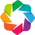

:Overlay
   .Curve.I           :Curve   [x]   (y)
   .Path.A_8th_round  :Path   [x,y]
   .Path.A_9th_round  :Path   [x,y]
   .Path.A_10th_round :Path   [x,y]

In [20]:
import holoviews as hv
from holoviews import opts
hv.extension('bokeh')
curve = hv.Curve(trace.wave).opts(width=600, height=600)

# add boxes around last rounds
if PLATFORM == "CWLITEXMEGA" or PLATFORM == "CW303":
    line = hv.Path([(11600, -0.25), (11600, 0.25), (13200, 0.25), (13200, -0.25), (11600, -0.25)], label='8th round').opts(color="red", show_legend=True) * \
            hv.Path([(13250, -0.25), (13250, 0.25), (14850, 0.25), (14850, -0.25), (13250, -0.25)], label='9th round').opts(color="green", show_legend=True) * \
            hv.Path([(14900, -0.25), (14900, 0.25), (16000, 0.25), (16000, -0.25), (14900, -0.25)], label='10th round').opts(color="yellow", show_legend=True)
elif PLATFORM == "CWLITEARM" or PLATFORM == "CW308_STM32F4":
    line = hv.Path([(5050, -0.1), (5050, 0.2), (5740, 0.2), (5740, -0.1), (5050, -0.1)], label='8th round').opts(color="red", show_legend=True) * \
            hv.Path([(5740, -0.1), (5740, 0.2), (6425, 0.2), (6425, -0.1), (5740, -0.1)], label='9th round').opts(color="green", show_legend=True) * \
            hv.Path([(6425, -0.1), (6425, 0.2), (6820, 0.2), (6820, -0.1), (6425, -0.1)], label='10th round').opts(color="yellow", show_legend=True)
    pass

(curve * line).opts(opts.Path(line_width=3)).opts(width=600, height=600)

In [21]:
# for scope.glitch.width:
# These width/offset numbers are for CW-Lite/Pro; for CW-Husky, convert as per Fault 1_1:
if PLATFORM == "CWLITEXMEGA" or PLATFORM == "CW303":
    width_range = Range(7*MIN_STEP, 8*MIN_STEP, MIN_STEP)
    offset_range = Range(0.4, 1.4, MIN_STEP)
    extoffset_range = Range(12800, 14100, 5)
    glitch_repeat = 5
elif PLATFORM == "CWLITEARM" or PLATFORM == "CW308_STM32F4":
    # Set all ranges first
    gc.set_global_step(0.4)
    gc.set_range("width", 100, 700) #600 nix interessantes
    gc.set_range("offset", 3900, 4600)
    gc.set_range("ext_offset", 5550, 5950)

    # Then apply individual step sizes
    gc.set_step("width", 50)
    gc.set_step("offset", 50)
    gc.set_step("ext_offset", 0.4)

    # gc.set_range("width", 600, 700)
    # gc.set_range("offset", 0, 4600)
    # gc.set_range("ext_offset", 5550, 5950)
    # gc.set_global_step(0.4)
    scope.glitch.repeat = 1

The next cell runs the glitches campaign. Until you disconnect the Chipwhisperer, you can re-run the campaign and analyze its results several times.  
Even when the parameters are perfectly maintained, the glitch effects are never twice exactly the same and the results of our campaigns may vary quite a lot.  
Adjust these parameters if you don't get proper results. Roughly:
* Grab your glitch settings from Fault101
* Avoid increasing too much `scope.glitch.repeat` as you don't want to inject mutiple faults affecting several bytes at once
* Beware of the effect of an oscilloscope probe if you're monitoring the glitches

The goal is to collect as many *interesting* outputs as possible. An *interesting* output at this stage is simply a 16-byte output different from the reference output.

In [22]:
print(scope.errors)

sam_errors      = False
sam_led_setting = Default
XADC errors     = False
ADC errors      = ADC clipped, 
extclk error    = False
trace errors    = False



In [26]:
gc.display_stats()
campaign()

IntText(value=0, description='column0 count:', disabled=True)

IntText(value=0, description='column1 count:', disabled=True)

IntText(value=0, description='column2 count:', disabled=True)

IntText(value=0, description='column3 count:', disabled=True)

IntText(value=0, description='other count:', disabled=True)

...

IntText(value=0, description='normal count:', disabled=True)

FloatSlider(value=100.0, continuous_update=False, description='width setting:', disabled=True, max=700.0, min=…

FloatSlider(value=3900.0, continuous_update=False, description='offset setting:', disabled=True, max=4600.0, m…

FloatSlider(value=5550.0, continuous_update=False, description='ext_offset setting:', disabled=True, max=5950.…

(ChipWhisperer Glitch WARNING|File ChipWhispererGlitch.py:196) clkgen unsupported for Husky; using pll instead.


In [45]:
gc.glitch_values()

<generator object GlitchController.glitch_values at 0x78268d35c740>

In [22]:
import csv

def save_traces(filename="traces_husky.csv"):
    if not traces:
        print("No traces captured yet.")
        return
    
    with open(filename, "w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow(["Category", "Glitch Width", "Glitch Offset", "Ext Offset"] + [f"Sample_{i}" for i in range(len(traces[0]))])
        
        for trace, category, glitch_params in zip(traces, categories, glitch_params_list):
            writer.writerow([category] + list(glitch_params) + list(trace))
    
    print(f"Saved {len(traces)} traces to {filename}")

print("Trace export function ready. Run save_traces() to save collected traces.")

save_traces()

Trace export function ready. Run save_traces() to save collected traces.
Saved 111524 traces to traces_husky.csv


Let's see the results:

In [23]:
from terminaltables import AsciiTable
table = AsciiTable(results)
print(table.table)

+----------------------------------+-------+--------+-----------+--------------+
| target output                    | width | offset | extoffset | column_fault |
+----------------------------------+-------+--------+-----------+--------------+
| 50fe67cc996d32b6da0937e99bafec60 | 600   | 0      | 5550      | None         |
| 50fe67cc996d32b6da0937e99bafec60 | 600   | 0      | 5550      | None         |
| 50fe67cc996d32b6da0937e99bafec60 | 600   | 0      | 5551      | None         |
| 50fe67cc996d32b6da0937e99bafec60 | 600   | 0      | 5551      | None         |
| 50fe67cc996d32b6da0937e99bafec60 | 600   | 0      | 5552      | None         |
| 50fe67cc996d32b6da0937e99bafec60 | 600   | 0      | 5552      | None         |
| 50fe67cc996d32b6da0937e99bafec60 | 600   | 0      | 5553      | None         |
| 50fe67cc996d32b6da0937e99bafec60 | 600   | 0      | 5553      | None         |
| 50fe67cc996d32b6da0937e99bafec60 | 600   | 0      | 5554      | None         |
| 50fe67cc996d32b6da0937e99b

Single we recorded which column each glitch was in, we can also plot where in `ext_offset` each successful glitch was. You can use either `width` or `offset` for the y-axis. In fact, try both!

In [ ]:
import csv

# def save_relevant_traces(filename="traces_husky_glitch.csv"):
def save_relevant_traces(filename="traces_other_reset_husky.csv"):
    """
    Saves only the traces that correspond to single-column glitches (column0, column1, column2, column3).
    Excludes normal, reset, and other traces.
    """
    relevant_categories = {"other", "reset"}
    #relevant_categories = {"column0", "column1", "column2", "column3"}
    count = 0  # Count actual saved traces
    
    with open(filename, mode="w", newline="") as file:
        writer = csv.writer(file)
        
        # Write header
        writer.writerow(["Category", "Width", "Offset", "ExtOffset", "Trace"])
        
        # Write only relevant traces
        for i in range(len(traces)):
            if categories[i] in relevant_categories:
                writer.writerow([
                    categories[i],  # Column category
                    glitch_params_list[i][0],  # Width
                    glitch_params_list[i][1],  # Offset
                    glitch_params_list[i][2],  # ExtOffset
                    ",".join(map(str, traces[i]))  # Convert trace to comma-separated string
                ])
                count += 1
    
    print(f"✅ Saved {count} relevant traces to {filename}")
save_relevant_traces()

✅ Saved 302 relevant traces to traces_other_reset_husky.csv


In [24]:
%matplotlib notebook
gc.results.plot_2d(plotdots={"column0":"+g", "column1":"pr", "column2":"bo", 
                             "column3":"sk", "normal":None, "other":None, "reset":None},
                   x_index=2, y_index=0)

[0, 1, 2]
['width', 'ext_offset']
(600, 5550)


:Overlay
   .Points.I       :Points   [Ext_Offset,Width]
   .Points.Column0 :Points   [ext_offset,width]   (column0_rate)
   .Points.Column1 :Points   [ext_offset,width]   (column1_rate)
   .Points.Column2 :Points   [ext_offset,width]   (column2_rate)
   .Points.Column3 :Points   [ext_offset,width]   (column3_rate)

We can also plot where we got resets and "other" results (glitches that didn't fault each byte in a single column). You can see there's way more "other" results and resets than successful glitches.

In [25]:
%matplotlib notebook
gc.results.plot_2d(plotdots={"column0":"^g", "column1":"vg", "column2":"<g", 
                             "column3":">g", "normal":None, "other":"b.", "reset":"rx"},
                   x_index=2, y_index=0)

[0, 1, 2]
['width', 'ext_offset']
(600, 5550)


:Overlay
   .Points.I       :Points   [Ext_Offset,Width]
   .Points.Column0 :Points   [ext_offset,width]   (column0_rate)
   .Points.Column1 :Points   [ext_offset,width]   (column1_rate)
   .Points.Column2 :Points   [ext_offset,width]   (column2_rate)
   .Points.Column3 :Points   [ext_offset,width]   (column3_rate)
   .Points.Other   :Points   [ext_offset,width]   (other_rate)
   .Points.Reset   :Points   [ext_offset,width]   (reset_rate)

### R9: Cryptanalysis of the faulty outputs

We'll use `phoenixAES` to perform the DFA against the collected ciphertexts.

All it requires is the list of *interesting* outputs and the reference output.

In [40]:
import phoenixAES
r10=phoenixAES.crack_bytes(outputs, goldciph, encrypt=True, verbose=2)

0261ca861b70f156efd9e00663a13a47: group None
60f6c58977ac8af7b73641a0c42a8f40: group None
7563d9b175e4f9360f59876eab1408eb: group None
964ff98a5b053a76b71a616e44278537: group None
8050acd0b6c9f23b2448fec8373e818a: group None
fb8984c5f18e3469c7d80c2aac5fda1e: group None
327a8b94973a0c2c0e2a4c4c35f130ca: group None
2df39d2f5f3b6d360f287d746ec347cd: group None
844ce1b576bb32d7df089d03d30c5474: group None
d0693a2100695faa7f7612411aadea9e: group None
00f922a1973212b170c7d3b84e0c1be1: group None
01a909fd361534a801e6f6d279aaab7e: group None
1bfd1eda22cc7ca4ec90ea71ed775f59: group None
1bfd1eda22cc7ca4ec90ea71ed775f59: group None
448c9be75f98cb266e92a015d77fbff2: group None
b26d93ba0b81e0b0754e383cb6017978: group None
b26d93ba0b81e0b0754e383cb6017978: group None
ffedd9a999978f34ada68da274778103: group None
09cc606ffdfa23956ac2119153df16d9: group None
e1add3b8e0ed2b5e69ad91f108a0edfb: group None
e1add3b8e0ed2b5e69ad91f108a0edfb: group None
c4171f3fea7bdd0d34efe3cb8a420e82: group None
36ec180c60

You can get a much cleaner output by only inserting single column faults:

In [41]:
r10=phoenixAES.crack_bytes(obf, goldciph, encrypt=True, verbose=2)

5efe67cc996d3201da09c0e99b58ec60: group 0
8afe67cc996d320cda09f9e99bb7ec60: group 0
Round key bytes recovered:
D0............89....0C....63....
50fe6766996db1b6da5637e908afec60: group 3
50fe6766996db1b6da5637e908afec60: group 3
50fe6737996d68b6da3037e970afec60: group 3
Round key bytes recovered:
D0....A8....2589..3F0C..B663....
50fe6766996db1b6da5637e908afec60: group 3
50fe6766996db1b6da5637e908afec60: group 3
50fe6766996db1b6da5637e908afec60: group 3
50fe6766996db1b6da5637e908afec60: group 3
50fe6766996db1b6da5637e908afec60: group 3
50fe6766996db1b6da5637e908afec60: group 3
50fe6766996db1b6da5637e908afec60: group 3
50fe6766996db1b6da5637e908afec60: group 3
50fe6766996db1b6da5637e908afec60: group 3
50fe6766996db1b6da5637e908afec60: group 3
50fe6766996db1b6da5637e908afec60: group 3
50fe6766996db1b6da5637e908afec60: group 3
50fe6766996db1b6da5637e908afec60: group 3
50fe6766996db1b6da5637e908afec60: group 3
50fe6766996db1b6da5637e908afec60: group 3
50fe6766996db1b6da5637e908afec60: group 

In this first attack, we assume the fault was injected *between* the last two *MixColumn* operations and we look for ciphertexts only partially (25%) corrupted.  
We hope you managed to recover the full 10th round key. If not, you may try again [from here](#R9:-Collecting-faulty-outputs) :) If you got very few or no "interesting" ciphertexts, better to tune `width_range`.   
Once the last round key is recovered, you can revert the AES keyscheduling and reveal the actual AES key.

In [91]:
r9_key=None
if r10 is not None:
    from chipwhisperer.analyzer.attacks.models.aes.key_schedule import key_schedule_rounds
    r9_key = key_schedule_rounds(bytearray.fromhex(r10), 10, 0)
    print("AES Key:")
    print(''.join("%02x" % x for x in r9_key))
else:
    print("Sorry, no key found, try another campain, maybe with different parameters...")

ValueError: non-hexadecimal number found in fromhex() arg at position 2

### R9: Plotting inner states differences

Once the AES key is known, we can display where the actual faults were injected, here plotting the first 10 outputs. 

In [ ]:
%run "../../Helper_Scripts/AES_differential_plotter.ipynb"
curve = None
if r9_key is not None:
    ad=AesDiff(intext=text, key=r9_key, encrypt=True)
    for c in outputs[:20]:
        ad.add_glitch(c)
    curve=ad.plot_diff_bits()
    if curve:
        curve
        curve *= hv.Path([(0, 8), (10, 8)], label='8 bits faulted').opts(color="red", show_legend=True)
    pass
curve.opts(width=600, height=600)

This graph displays the difference in bits between the goldciph and the faulty ciphertext at the output of each round. Of course the plot only makes sense from the lowest points of the curve to the right, there is no fault diffusion from the fault to the left.
We're more interested in the number of bytes which are faulted before the last *MixColumn*:

In [ ]:
curve=None
if r9_key is not None:
    curve=ad.plot_diff_bytes()
    curve
    curve *= hv.Path([(0, 1), (10, 1)], label='1 byte faulted').opts(color="red", show_legend=True)
curve.opts(width=600, height=600)

We also kept track of which outputs faulted a single column. We can plot all of these single column fault here:

In [ ]:
%run "../../Helper_Scripts/AES_differential_plotter.ipynb"
curve = None
if r9_key is not None:
    ad=AesDiff(intext=text, key=r9_key, encrypt=True)
    for c in obf[:]:
        ad.add_glitch(c)
    curve=ad.plot_diff_bits()
    if curve:
        curve *= hv.Path([(0, 8), (10, 8)], label='8 bits faulted').opts(color="red", show_legend=True)
curve.opts(width=600, height=600)

You should hopefully see mostly single byte faults here (you're looking for one byte to be wrong in the 8th round output). Otherwise multiple bytes in the column were faulted and we can't use that output to break the key! These faults are all on a single column, so they end up affecting 4 bytes of output.

In [ ]:
curve=None
if r9_key is not None:
    curve=ad.plot_diff_bytes()
    curve *= hv.Path([(0, 1), (10, 1)], label='1 byte faulted').opts(color="red", show_legend=True)
curve.opts(width=600, height=600)

We managed to break the key because indeed a number of executions was properly faulted on a single byte before the last *MixColumn*, cf the lowest curves at position 8.

## Attacking the 8th round

To reduce the number of required faults, we can inject glitches one round earlier.
If the faults are injected one *MixColumn* earlier, in the 8th round, the ciphertext will be completely corrupted.
But we can still apply the same cryptanalysis!
The trick is to convert one such fault into four faults on the 9th round.

### R8: Collecting faulty outputs

Let's change our parameters to attack one round earlier and launch our attack. We're still doing the single byte display, but this time you shouldn't see any single column faults. Instead, both good and bad faults are grouped into "other".

In [ ]:
# for scope.glitch.ext_offset:
if PLATFORM == "CWLITEXMEGA" or PLATFORM == "CW303":
    extoffset_range = Range(11800, 12400, 3)
elif PLATFORM == "CWLITEARM" or PLATFORM == "CW308_STM32F3":
    gc.set_range("ext_offset", 5050, 5250)
gc.display_stats()
campaign()

Let's see the results:

In [ ]:
from terminaltables import AsciiTable
table = AsciiTable(results)
print(table.table)

### R8: Cryptanalysis of the faulty outputs

In this second attack, we assume the fault was injected *before* the last two *MixColumn* operations.
First, we convert each 100% faulty output into four 25% faulty outputs and then we apply the same attack as before.

In [ ]:
outputs2=phoenixAES.convert_r8faults_bytes(outputs, goldciph, encrypt=True)
r10=phoenixAES.crack_bytes(outputs2, goldciph, encrypt=True, verbose=2)

We hope you managed to recover the full 10th round key. If not, you may try again [from here](#R8:-Collecting-faulty-outputs). 
Once the last round key is recovered, you can revert the AES keyscheduling and reveal the actual AES key.

In [ ]:
if r10 is not None:
    from chipwhisperer.analyzer.attacks.models.aes.key_schedule import key_schedule_rounds
    key = key_schedule_rounds(bytearray.fromhex(r10), 10, 0)
    print("AES Key:")
    print(''.join("%02x" % x for x in key))
else:
    print("Sorry, no key found, try another campain, maybe with different parameters...")

### R8: Plotting inner states differences

Let's plot the fault diffusion of the first 10 outputs.

In [ ]:
%run "../../Helper_Scripts/AES_differential_plotter.ipynb"
curve=None
if key is not None:
    ad=AesDiff(intext=text, key=key, encrypt=True)
    for c in outputs[:100]:
        ad.add_glitch(c)
    curve=ad.plot_diff_bits()
    if curve:
        curve
        curve *= hv.Path([(0, 8), (10, 8)], label='8 bits faulted').opts(color="red", show_legend=True)
curve.opts(width=600, height=600)

And grouped by faulty bytes. We now see that we get single byte faults one round earlier:

In [ ]:
curve = None
if key is not None:
    curve=ad.plot_diff_bytes()
    if curve:
        curve.opts(width=600, height=600)
curve

## The end

Once you're done, clean up the connection to the scope and target.  
**Warning**, once disconnected, you'll have to run the cells since the [CW-lite connection and target flashing](#CW-lite-connection-and-target-flashing) section to be connected again.

In [ ]:
scope.dis()
target.dis()

This tutorial is over.  
You might now try to attack other instances by yourself, e.g. recompile the target with `CRYPTO_TARGET = "TINYAES128C"` and try to break it!

## Tests

In [ ]:
assert key == [43, 126, 21, 22, 40, 174, 210, 166, 171, 247, 21, 136, 9, 207, 79, 60], "Failed to break r8"

In [ ]:
assert r9_key == [43, 126, 21, 22, 40, 174, 210, 166, 171, 247, 21, 136, 9, 207, 79, 60], "Failed to break r9"